## Окружение

Создайте окружение `sc_pbmc` в терминале Linux (или терминале JupyterLab) и зарегистрируйте его как ядро Jupyter. `scikit-misc` необходим для отбора HVG методом `seurat_v3`.

```bash
mamba create -n sc_pbmc -c conda-forge python=3.11 scanpy scikit-misc jupyterlab ipykernel -y
mamba activate sc_pbmc
python -m ipykernel install --user --name sc_pbmc --display-name "sc_pbmc"
```

Выберите ядро **Python (sc_pbmc)**. Если `mamba` отсутствует, замените `mamba create` на `conda create`.

## Данные

**PBMC 3k** — клетки периферической крови здорового донора, секвенированные с помощью 10x Genomics (около 2700 клеток). Ниже скачивается исходная матрица UMI counts в формате Matrix Market, включая файлы генов и клеточных штрихкодов. После распаковки они окажутся в `data/filtered_gene_bc_matrices/hg19/`.

Источник: [10x Genomics — PBMC 3k](https://www.10xgenomics.com/datasets/3-k-pbm-cs-from-a-healthy-donor-1-standard-1-0-0) · [документация Scanpy](https://scanpy.readthedocs.io/en/latest/api/generated/scanpy.datasets.pbmc3k.html).

In [1]:
%pip install -q "scanpy>=1.11,<2" scikit-misc leidenalg igraph numpy pandas scipy matplotlib scikit-learn umap-learn h5py ipython

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.


In [2]:
from pathlib import Path
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.stats import spearmanr
from scipy.sparse.csgraph import connected_components
from IPython.display import display
sc.set_figure_params(dpi=90, frameon=False)
np.random.seed(42)
Path("data").mkdir(exist_ok=True)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [3]:
!mkdir -p data
!curl -fL https://cf.10xgenomics.com/samples/cell-exp/1.1.0/pbmc3k/pbmc3k_filtered_gene_bc_matrices.tar.gz -o data/pbmc3k.tar.gz
!tar -xzf data/pbmc3k.tar.gz -C data

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 7443k  100 7443k    0     0  11.7M      0 --:--:-- --:--:-- --:--:-- 11.7M


In [4]:
from urllib.request import urlretrieve
import tarfile
raw_folder = Path("data/filtered_gene_bc_matrices/hg19")
archive = Path("data/pbmc3k.tar.gz")
if not (raw_folder / "matrix.mtx").exists():
    if not archive.exists():
        urlretrieve("https://cf.10xgenomics.com/samples/cell-exp/1.1.0/pbmc3k/pbmc3k_filtered_gene_bc_matrices.tar.gz", archive)
    with tarfile.open(archive) as f:
        f.extractall("data", filter="data")

In [5]:
import scanpy as sc
import matplotlib.pyplot as plt
import numpy as np

In [6]:
adata = sc.read_10x_mtx("data/filtered_gene_bc_matrices/hg19/")

In [7]:
adata

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
    layers: None (.X)

In [8]:
adata.var

,gene_ids
MIR1302-10,ENSG00000243485
FAM138A,ENSG00000237613
OR4F5,ENSG00000186092
RP11-34P13.7,ENSG00000238009
RP11-34P13.8,ENSG00000239945
...,...
AC145205.1,ENSG00000215635
BAGE5,ENSG00000268590
CU459201.1,ENSG00000251180
AC002321.2,ENSG00000215616


In [9]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")

In [10]:
adata.var

,gene_ids,mt
MIR1302-10,ENSG00000243485,False
FAM138A,ENSG00000237613,False
OR4F5,ENSG00000186092,False
RP11-34P13.7,ENSG00000238009,False
RP11-34P13.8,ENSG00000239945,False
...,...,...
AC145205.1,ENSG00000215635,False
BAGE5,ENSG00000268590,False
CU459201.1,ENSG00000251180,False
AC002321.2,ENSG00000215616,False


In [11]:
adata.var_names[adata.var["mt"]]

Index(['MT-ND1', 'MT-ND2', 'MT-CO1', 'MT-CO2', 'MT-ATP8', 'MT-ATP6', 'MT-CO3',
       'MT-ND3', 'MT-ND4L', 'MT-ND4', 'MT-ND5', 'MT-ND6', 'MT-CYB'],
      dtype='str')

# Какие есть ещё поля в AnnData?

## Структура AnnData

Основная матрица имеет размер:

$$
\underbrace{C}_{\text{клетки}}
\times
\underbrace{G}_{\text{гены}}
$$

- **Строки** — клетки (observations).
- **Столбцы** — гены (variables).
- **Элементы** — значения экспрессии генов в клетках.

Здесь `adata.X` — название поля AnnData, а не матрица отдельных UMI $X_{ig}$ из нашей вероятностной модели. В `adata.X` мы обычно храним матрицу $Y_{ci}$.

### Основные поля AnnData

| Поле | Размерность | Что хранит |
|---|---|---|
| `adata.X` | $C\times G$ | Основная матрица экспрессии |
| `adata.obs` | $C\times K$ | Таблица характеристик клеток |
| `adata.var` | $G\times L$ | Таблица характеристик генов |
| `adata.obs_names` | $C$ | Идентификаторы клеток (индекс `obs`) |
| `adata.var_names` | $G$ | Идентификаторы генов (индекс `var`) |
| `adata.layers` | Каждая матрица $C\times G$ | Дополнительные версии матрицы экспрессии |
| `adata.obsm` | $C\times d$ | Многомерные представления клеток |
| `adata.varm` | $G\times d$ | Многомерные представления генов |
| `adata.obsp` | $C\times C$ | Матрицы отношений между клетками |
| `adata.varp` | $G\times G$ | Матрицы отношений между генами |
| `adata.uns` | Произвольная | Параметры, словари и другие результаты анализа |
| `adata.raw` | Снимок $C\times G_{\mathrm{raw}}$ | Сохранённые `X`, `var` и имена генов |

Здесь $K$ и $L$ — количества столбцов с метаданными, а $d$ — число измерений в многомерном представлении.

In [12]:
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, inplace=True)

In [13]:
 adata

AnnData object with n_obs × n_vars = 2700 × 32738
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    layers: None (.X)

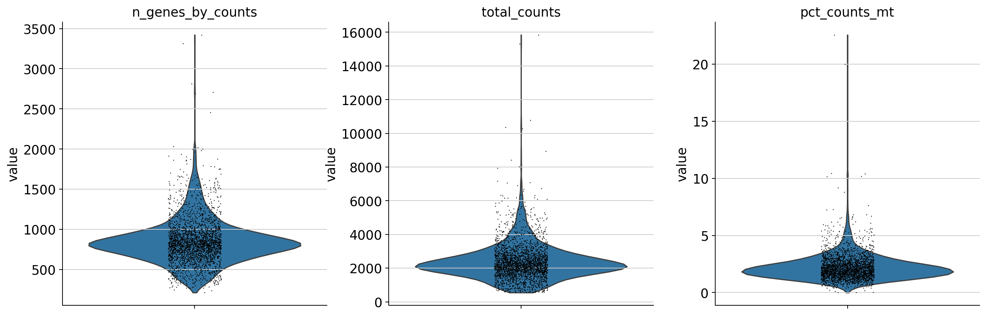

In [14]:
sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"], multi_panel=True)

In [15]:
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)

In [16]:
adata = adata[(adata.obs.n_genes_by_counts < 2500) & (adata.obs.pct_counts_mt < 5)].copy()

In [17]:
adata.layers["counts"] = adata.X.copy()

In [18]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    layers: None (.X), 'counts'

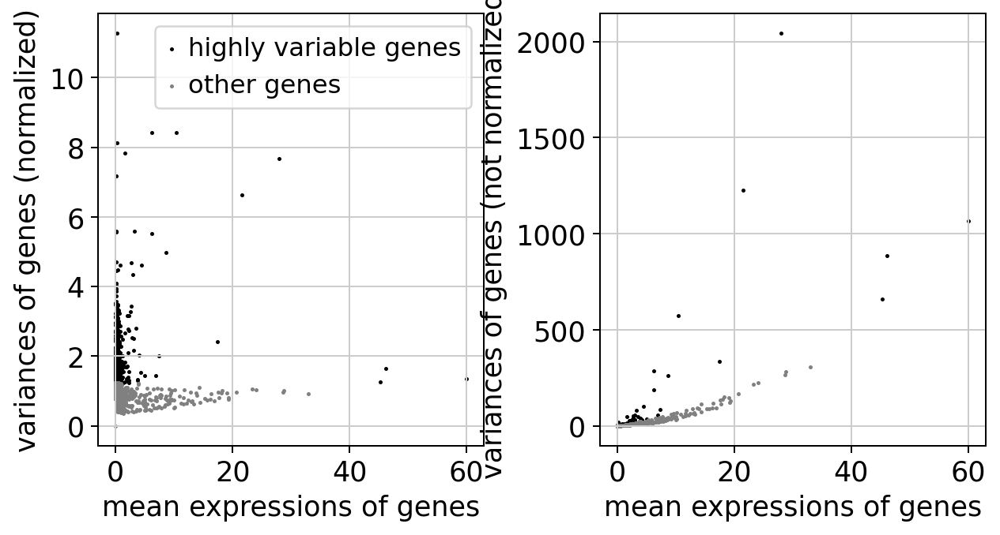

In [19]:
sc.pp.highly_variable_genes(adata, layer="counts", flavor="seurat_v3", n_top_genes=2000)
sc.pl.highly_variable_genes(adata)

In [20]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg'
    layers: None (.X), 'counts'

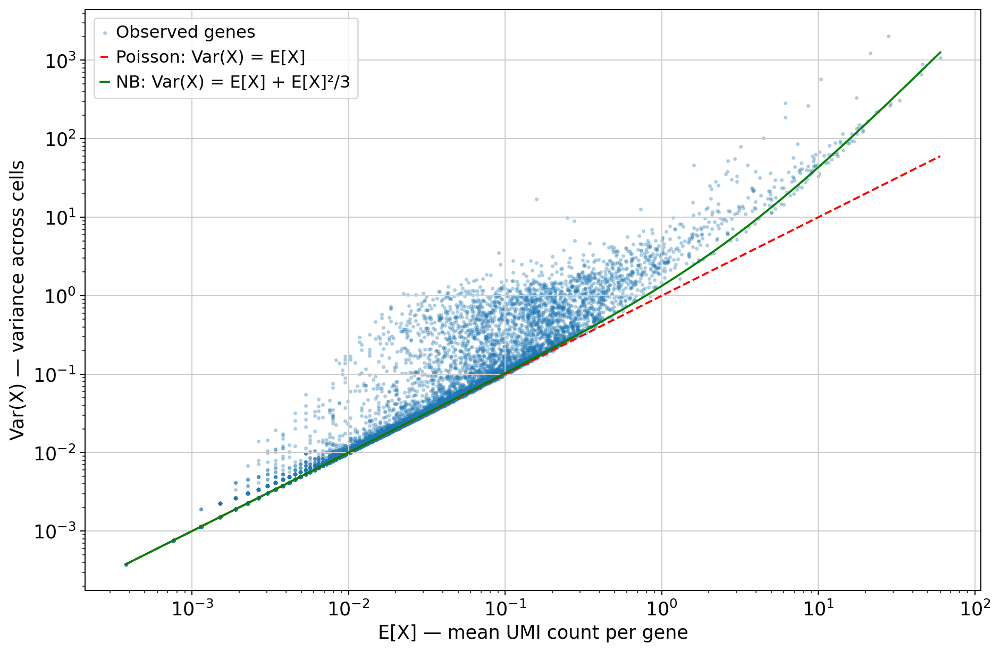

In [21]:
plt.figure(figsize=(12, 8))

mean = adata.var["means"].to_numpy()
var = adata.var["variances"].to_numpy()
valid = (mean > 0) & (var > 0)

theta = 3

x = np.geomspace(mean[valid].min(), mean[valid].max(), 200)

plt.scatter(mean[valid], var[valid], s=4, alpha=0.25, label="Observed genes")

plt.plot(x, x, "r--", label="Poisson: Var(X) = E[X]")
plt.plot(x, x + x**2/theta, "g-", label=f"NB: Var(X) = E[X] + E[X]²/{theta}")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("E[X] — mean UMI count per gene")
plt.ylabel("Var(X) — variance across cells")
plt.legend()
plt.show()

In [22]:
sc.pp.normalize_total(adata, target_sum=1e4) # учитываем разный размер библиотеки. Нормализуем на глубину секвенирования
sc.pp.log1p(adata) # уменьшаем влияние сильно экспрессируемых генов

In [24]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: None (.X), 'counts'

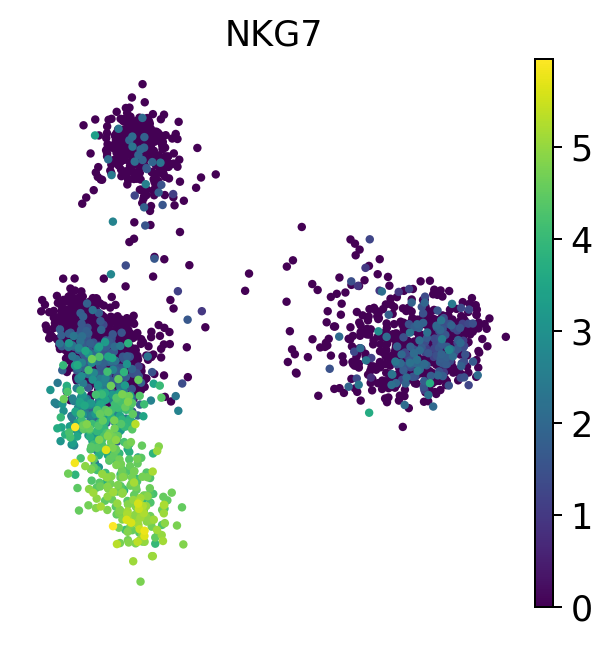

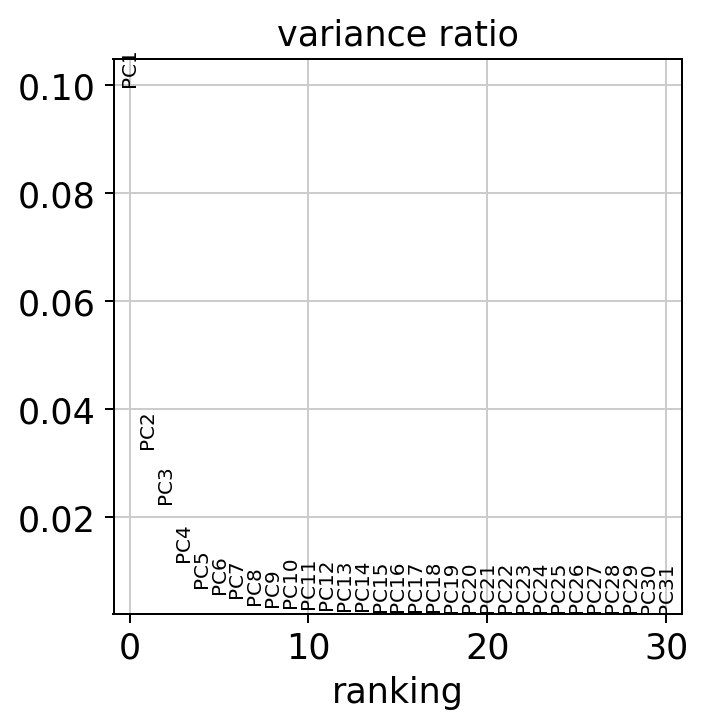

In [25]:
sc.tl.pca(adata, mask_var="highly_variable")
sc.pl.pca(adata, color="NKG7")
sc.pl.pca_variance_ratio(adata)

In [26]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: None (.X), 'counts'

## Подумайте

* Посмотрите что сейчас находится в слоях anndata. Что из себя представляют новые слои?
* По каким генам можно ещё делать QC?   
* Как лучше делать QC: по поиску генов по названиям в матрице или с помощью gtf/gff файла?
* Сколько есть генов на митохондриальной хросоме? Все ли они начинаются с mt?
* У человека митохондриальные гены начинаются с MT, у мыши с mt. Как начинаются митохондриальные гены у других организмов: у коров, собак, приматов?

В layers находится counts с исходными UMI, а в X лежат значения после нормализации и log1p. Результаты PCA записаны в obsm, varm и uns, отдельного слоя для них нет.

Для проверки качества также подходят RPS/RPL, гемоглобины и MALAT1. Их высокая доля может зависеть от типа и состояния клетки, поэтому это не всегда признак плохого качества.

Митохондриальные гены надежнее искать по GTF/GFF, а не только по названию. У человека их 37, из них 13 кодируют белки, 22 дают тРНК и 2 дают рРНК, но в матрице 10x видна лишь часть. У человека обычно используется MT-, у мыши mt-, а для коровы, собаки и других приматов нужно проверить названия в конкретной аннотации. Гены ядерного генома, связанные с работой митохондрий, в эти 37 не входят.

**Во всех заданиях если не сказано иного используйте анализ с использованием филтрации по QC и PCA с использованием HVG**

## Задание 1
Сделайте QC по предложенным вами генам/группам генов и постройти графики для всех QC - и тех что мы сделали сами и тех что вы предложили.

Для каждой группы генов/гена рассчитайте долю UMI от общего количества UMI клетки.

Постройте для всех QC-метрик (включая рассчитанные на занятии):

1. Violin plot.
2. Гистограмму распределения:
   - X — значение QC-метрики;
   - Y — количество клеток.
3. Scatter plot зависимости количества обнаруженных генов от общего количества UMI.

**Вопросы:** Какие клетки выглядят подозрительными? Какие метрики могут свидетельствовать о низком качестве клетки? Почему высокая доля определённой группы генов не всегда означает плохое качество?


In [27]:
markers = ["CD3D", "MS4A1", "NKG7", "LST1"]
def add_qc(a):
    a.var["mt"] = a.var_names.str.startswith("MT-")
    a.var["ribo"] = a.var_names.str.startswith(("RPS", "RPL"))
    a.var["hb"] = a.var_names.isin(["HBA1", "HBA2", "HBB", "HBD", "HBG1", "HBG2", "HBE1", "HBZ", "HBM", "HBQ1"])
    a.var["MALAT1"] = a.var_names == "MALAT1"
    sc.pp.calculate_qc_metrics(a, qc_vars=["mt", "ribo", "hb", "MALAT1"], percent_top=None, inplace=True)

def pca_variant(a, hvg=True, normalize=True, logarithm=True, scale=False):
    b = a.copy()
    if "counts" in b.layers:
        b.X = b.layers["counts"].copy()
    b.uns.pop("log1p", None)
    if hvg:
        sc.pp.highly_variable_genes(b, flavor="seurat_v3", n_top_genes=2000)
    if normalize:
        sc.pp.normalize_total(b, target_sum=1e4)
    if logarithm:
        sc.pp.log1p(b)
    if scale:
        sc.pp.scale(b, max_value=10)
    sc.tl.pca(b, n_comps=50, mask_var="highly_variable" if hvg else None, svd_solver="arpack", random_state=42)
    return b

def pc_correlations(a, fields):
    return pd.DataFrame({f"PC{i+1}": {k: spearmanr(a.obsm["X_pca"][:, i], a.obs[k]).statistic for k in fields} for i in range(2)})

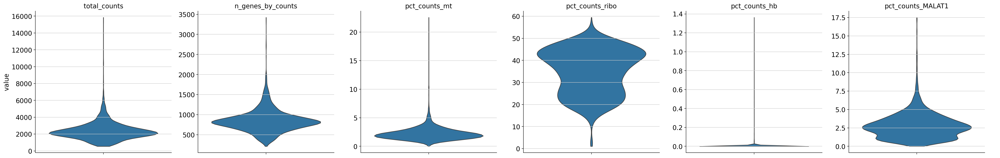

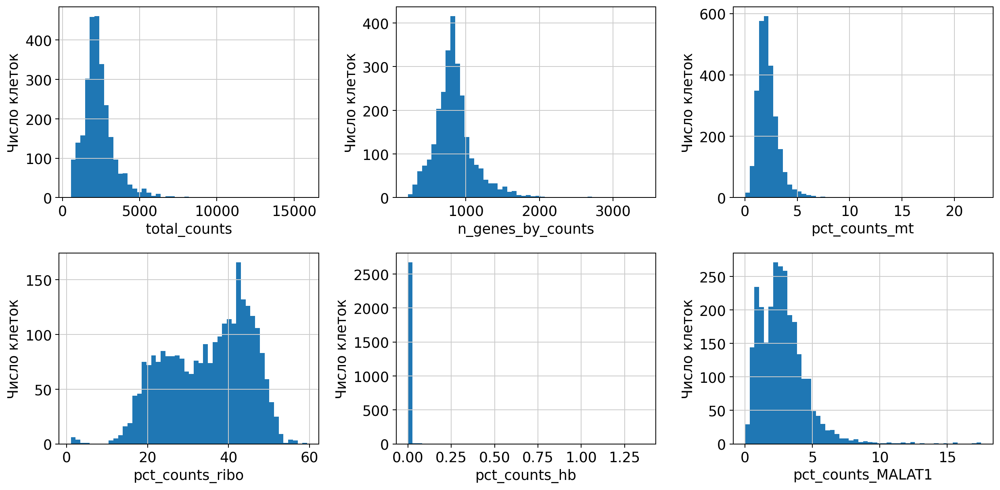

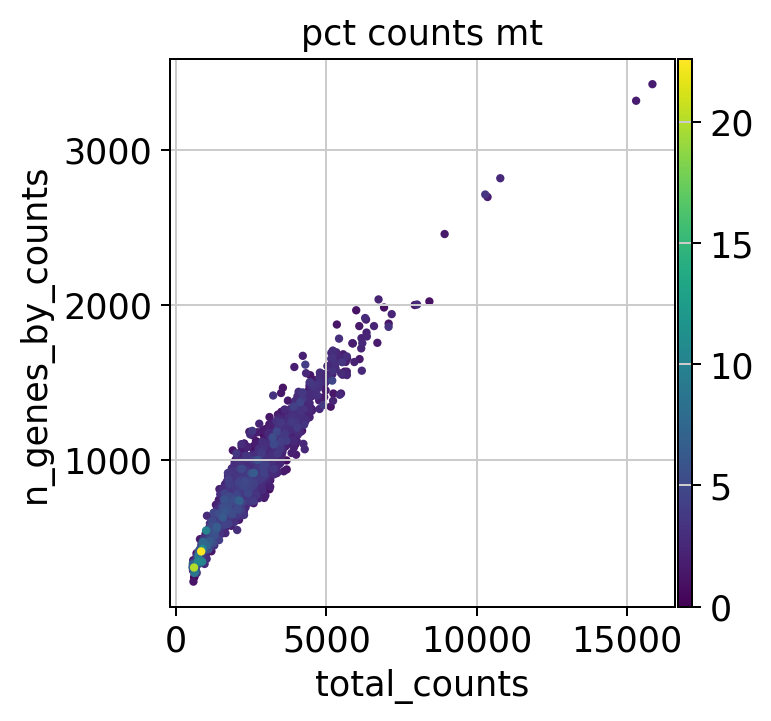

Гены в группах: {'mt': 13, 'ribo': 106, 'hb': 10, 'MALAT1': 1}
До QC: (2700, 32738)


,total_counts,n_genes_by_counts,pct_counts_mt,pct_counts_ribo,pct_counts_hb,pct_counts_MALAT1
count,2700.00,2700.00,2700.00,2700.00,2700.00,2700.00
mean,2366.90,846.99,2.22,34.95,0.00,2.81
std,1094.26,282.10,1.17,10.22,0.03,1.80
min,548.00,212.00,0.00,1.06,0.00,0.00
25%,1757.75,690.00,1.54,26.33,0.00,1.56
50%,2197.00,817.00,2.03,36.77,0.00,2.59
75%,2763.00,953.25,2.64,43.35,0.00,3.64
max,15844.00,3422.00,22.57,59.44,1.36,17.51


После QC: (2638, 13714)
Удалено клеток: 62


In [28]:
raw = sc.read_10x_mtx(raw_folder, var_names="gene_symbols", make_unique=True)
add_qc(raw)
qc_fields = ["total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo", "pct_counts_hb", "pct_counts_MALAT1"]
sc.pl.violin(raw, qc_fields, multi_panel=True, stripplot=False)
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, field in zip(axes.flat, qc_fields):
    ax.hist(raw.obs[field], bins=50)
    ax.set(xlabel=field, ylabel="Число клеток")
plt.tight_layout()
plt.show()
sc.pl.scatter(raw, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt")
print("Гены в группах:", raw.var[["mt", "ribo", "hb", "MALAT1"]].sum().to_dict())
print("До QC:", raw.shape)
display(raw.obs[qc_fields].describe().round(2))
filtered = raw.copy()
sc.pp.filter_cells(filtered, min_genes=200)
sc.pp.filter_genes(filtered, min_cells=3)
filtered = filtered[(filtered.obs.n_genes_by_counts < 2500) & (filtered.obs.pct_counts_mt < 5)].copy()
filtered.layers["counts"] = filtered.X.copy()
print("После QC:", filtered.shape)
print("Удалено клеток:", raw.n_obs - filtered.n_obs)

После QC осталось 2638 из 2700 клеток и 13714 генов, удалены 62 клетки. Подозрительны клетки с малым числом генов, большой долей митохондриальных UMI или необычно большим числом генов. До фильтрации митохондриальная доля доходила до 22,57%, а доля гемоглобинов до 1,36%. По высокой доле RPS/RPL клетки не удалялись, так как она может отражать их обычную работу.

## Задание 2. Сравнение методов отбора HVG

Мы использовали `seurat_v3`. Повторите отбор HVG методом `seurat`, а также попробуйте использовать `sc.experimental.pp.highly_variable_genes`.

Постройте PCA на генах, отобранных каждым методом. Для обоих PCA используйте одинаковую нормализованную и логарифмированную матрицу экспрессии.

Окрасьте клетки по экспрессии известных маркеров иммунных популяций:

| Популяция | Ген |
|---|---|
| T-клетки | `CD3D` |
| B-клетки | `MS4A1` |
| NK-клетки | `NKG7` |
| Моноциты | `LST1` |

Эти гены используются как ориентиры, а не как окончательные аннотации клеточных типов.

**Вопросы:** Насколько отличаются расположения клеток? Сохраняются ли группы клеток с характерной экспрессией маркеров? Сколько генов одновременно попало в оба набора HVG?


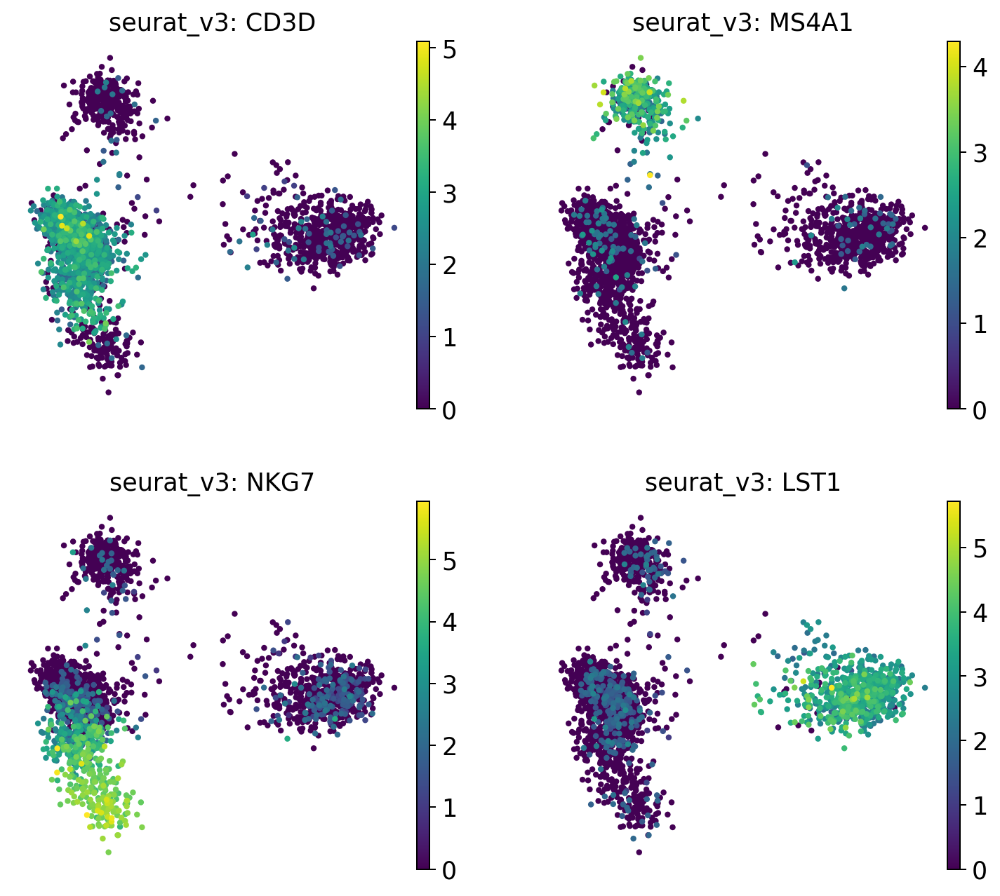

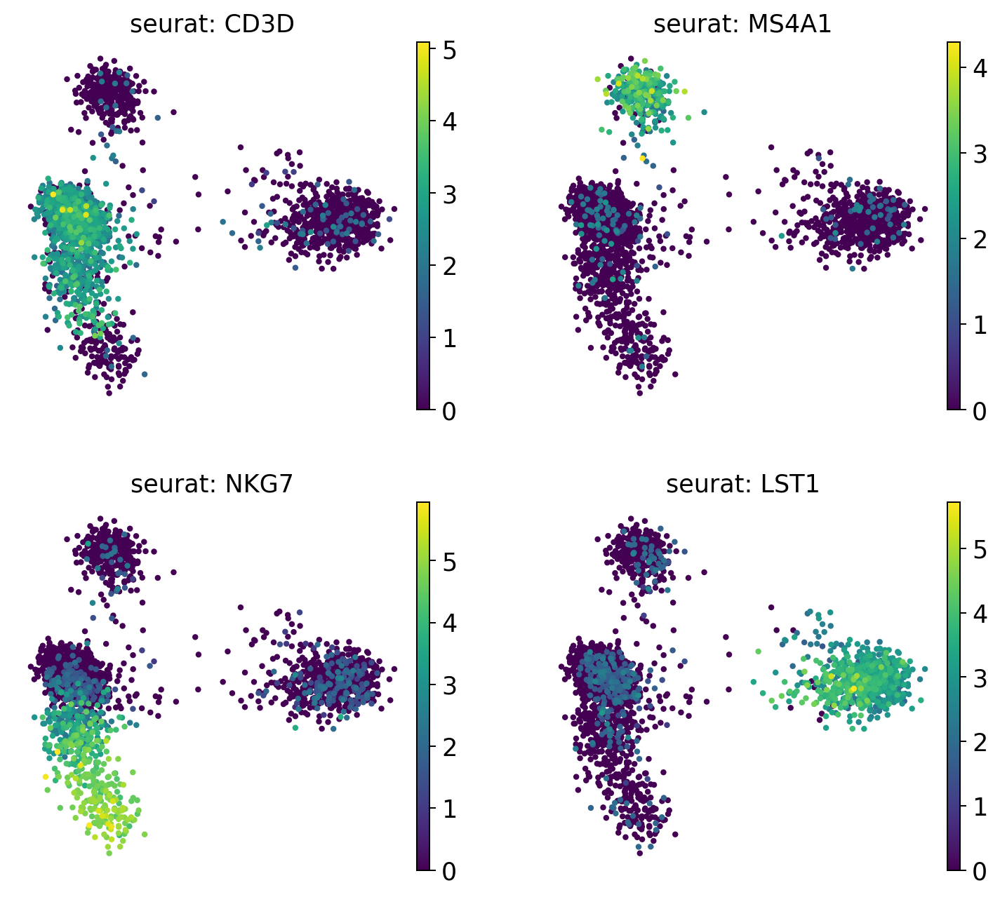

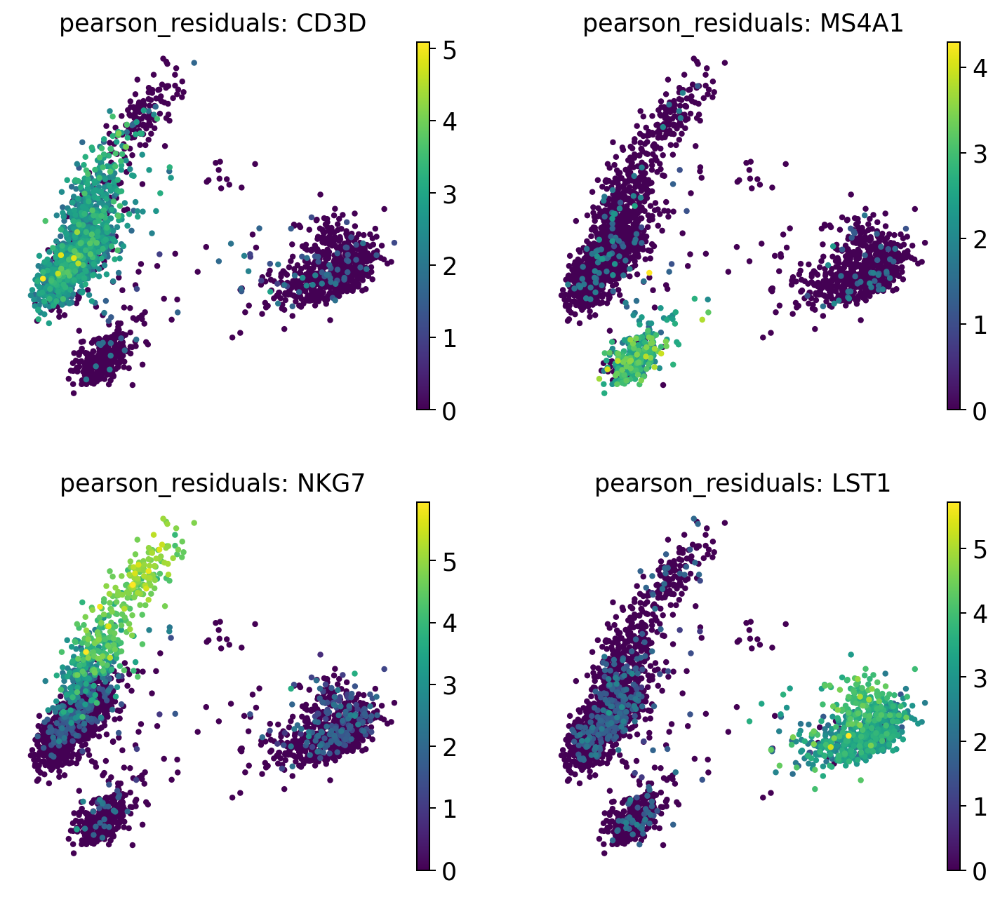

Пересечение наборов HVG:


,seurat_v3,seurat,pearson_residuals
seurat_v3,2000,1505,1402
seurat,1505,2000,1291
pearson_residuals,1402,1291,2000


seurat_v3 совпадение 15 соседей с seurat_v3: 1.0
seurat совпадение 15 соседей с seurat_v3: 0.263
pearson_residuals совпадение 15 соседей с seurat_v3: 0.221


In [29]:
base = filtered.copy()
sc.pp.normalize_total(base, target_sum=1e4)
sc.pp.log1p(base)
hvg_masks = {}
a = filtered.copy()
sc.pp.highly_variable_genes(a, layer="counts", flavor="seurat_v3", n_top_genes=2000)
hvg_masks["seurat_v3"] = a.var.highly_variable.to_numpy().copy()
a = base.copy()
sc.pp.highly_variable_genes(a, flavor="seurat", n_top_genes=2000)
hvg_masks["seurat"] = a.var.highly_variable.to_numpy().copy()
a = filtered.copy()
sc.experimental.pp.highly_variable_genes(a, layer="counts", flavor="pearson_residuals", n_top_genes=2000)
hvg_masks["pearson_residuals"] = a.var.highly_variable.to_numpy().copy()
pca_methods = {}
for method, mask in hvg_masks.items():
    a = base.copy()
    a.var["highly_variable"] = mask
    sc.tl.pca(a, n_comps=50, mask_var="highly_variable", svd_solver="arpack", random_state=42)
    pca_methods[method] = a
    sc.pl.pca(a, color=markers, ncols=2, title=[f"{method}: {g}" for g in markers])
overlap = pd.DataFrame({m: {n: int(np.sum(hvg_masks[m] & hvg_masks[n])) for n in hvg_masks} for m in hvg_masks})
print("Пересечение наборов HVG:")
display(overlap)
from sklearn.neighbors import NearestNeighbors
reference = pca_methods["seurat_v3"].obsm["X_pca"][:, :30]
ref_neighbors = NearestNeighbors(n_neighbors=16).fit(reference).kneighbors(reference, return_distance=False)[:, 1:]
for name, a in pca_methods.items():
    xy = a.obsm["X_pca"][:, :30]
    idx = NearestNeighbors(n_neighbors=16).fit(xy).kneighbors(xy, return_distance=False)[:, 1:]
    retained = np.mean([len(set(x) & set(y))/15 for x, y in zip(ref_neighbors, idx)])
    print(name, "совпадение 15 соседей с seurat_v3:", round(retained, 3))

Каждый метод выбрал 2000 HVG, а общих генов оказалось 1505 для seurat_v3 и seurat, 1402 для seurat_v3 и Pearson residuals и 1291 для seurat и Pearson residuals. Основные группы клеток сохраняются, хотя их форма и положение меняются, особенно при Pearson residuals. Все PCA построены на одинаково обработанных данных, но совпадение 15 ближайших соседей с seurat_v3 составляет только 26,3% для seurat и 22,1% для Pearson residuals.

## Задание 3. PCA без отбора HVG

Повторите PCA, используя все гены, прошедшие QC, без ограничения набором HVG.

Сравните результат с PCA, построенным по 2000 HVG.

Используйте те же маркеры и одинаковые настройки нормализации и масштабирования данных.

**Вопросы:** Как изменилась структура клеток? Какие компоненты объясняют больше дисперсии? Почему использование всех доступных генов не обязательно делает PCA информативнее?


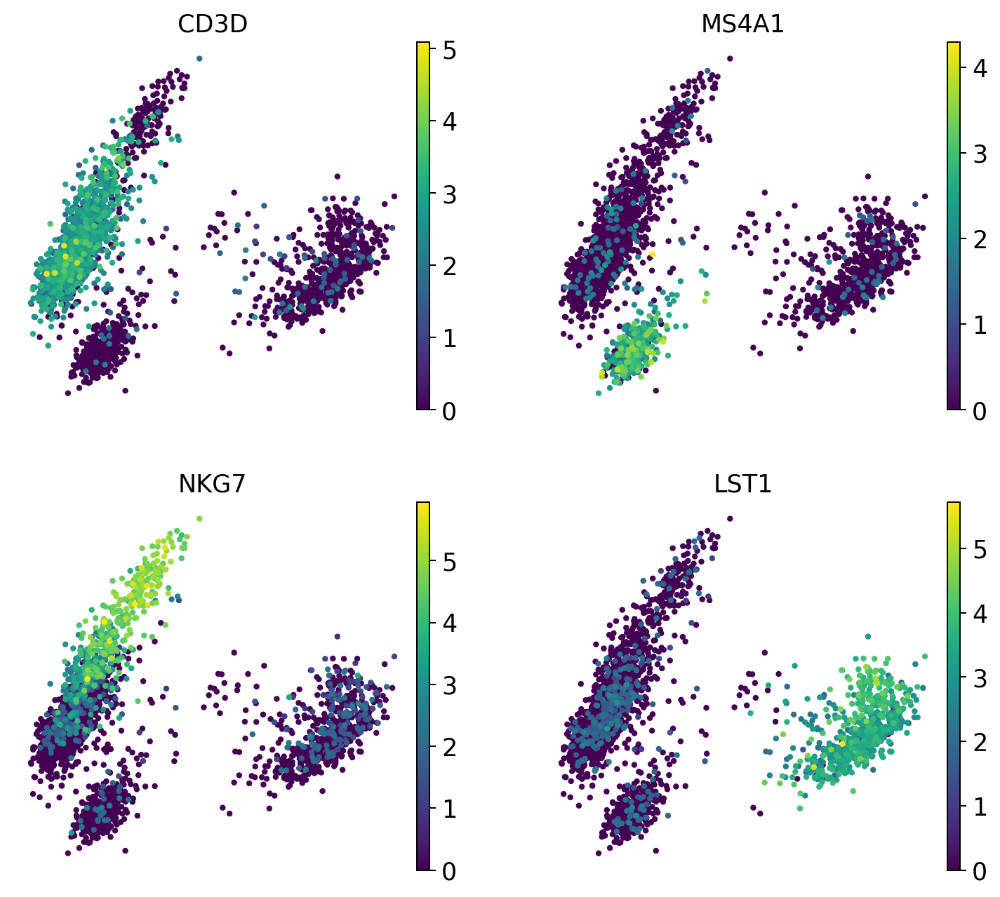

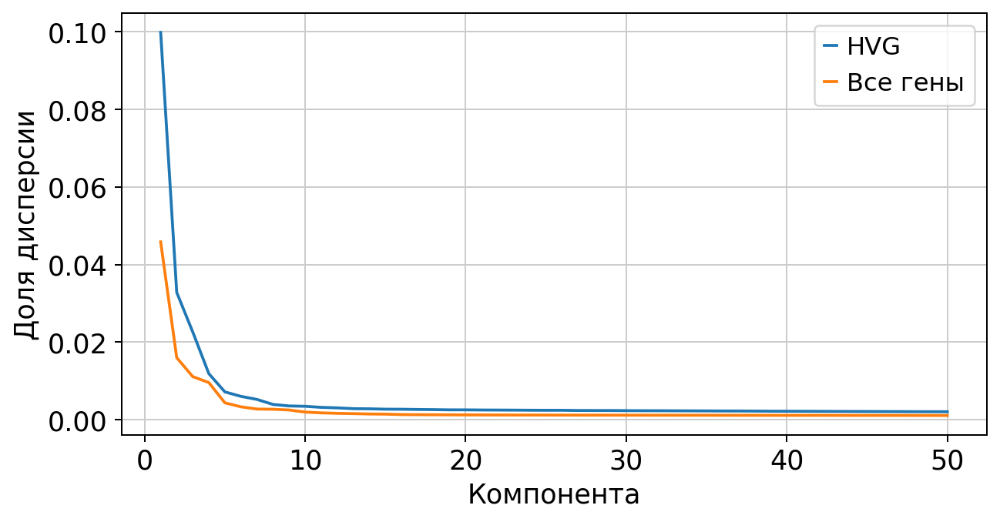

,HVG,Все гены
1,0.0998,0.0458
2,0.0328,0.0160
3,0.0226,0.0111
4,0.0119,0.0096
5,0.0072,0.0044
6,0.0060,0.0034
7,0.0053,0.0028
8,0.0040,0.0027
9,0.0036,0.0025
10,0.0035,0.0020


Доля дисперсии PC1+PC2: {'HVG': 0.13259999454021454, 'Все гены': 0.061799999326467514}


In [30]:
all_genes_pca = base.copy()
sc.tl.pca(all_genes_pca, n_comps=50, mask_var=None, svd_solver="arpack", random_state=42)
sc.pl.pca(all_genes_pca, color=markers, ncols=2)
hvg_pca = pca_methods["seurat_v3"]
variance_comparison = pd.DataFrame({"HVG": hvg_pca.uns["pca"]["variance_ratio"], "Все гены": all_genes_pca.uns["pca"]["variance_ratio"]}, index=np.arange(1, 51))
variance_comparison.plot(xlabel="Компонента", ylabel="Доля дисперсии", figsize=(8, 4))
plt.show()
display(variance_comparison.head(10).round(4))
print("Доля дисперсии PC1+PC2:", variance_comparison.head(2).sum().round(4).to_dict())

Группы с CD3D, MS4A1, NKG7 и LST1 сохраняются. На HVG первые две компоненты объясняют 13,26% разброса данных, а на всех генах 6,18%, но эти доли относятся к разным наборам генов. Добавление всех генов не обязательно помогает, так как вместе с ними добавляется много слабого сигнала и шума.

## Задание 4. HVG и уровень экспрессии

Получите два списка:

- Гены, отобранные как HVG.
- Гены, не попавшие в HVG.

В каждом списке найдите 50 генов с наибольшим средним количеством UMI на клетку по исходным counts.

Сравните средний уровень экспрессии, дисперсию и известные функции этих генов.

**Вопросы:** Обязательно ли HVG являются наиболее экспрессируемыми генами? Почему ген может иметь очень высокую экспрессию, но не попасть в HVG? Какие группы генов встречаются среди наиболее экспрессируемых?


HVG 50 самых экспрессируемых генов


,mean_umi,variance,HVG
MALAT1,60.036732,1066.570312,True
TMSB4X,46.140289,883.349854,True
B2M,45.289223,659.148682,True
FTL,27.999430,2041.886475,True
FTH1,21.535463,1224.520508,True
ACTB,17.458569,334.396576,True
LYZ,10.408192,575.139343,True
CD74,8.579643,261.793152,True
S100A4,7.343126,86.244446,True
MT-CO2,6.888643,56.957253,True


Среднее UMI / медиана дисперсии: 7.149 29.46
Не HVG 50 самых экспрессируемых генов


,mean_umi,variance,HVG
RPL10,33.017464,307.453003,False
RPL13,28.774101,280.543518,False
RPL13A,28.644434,264.611633,False
RPS2,24.092089,222.750671,False
RPS6,23.292944,217.958923,False
RPS18,20.609489,166.668060,False
RPL11,19.285789,128.377533,False
RPL32,19.239534,122.027008,False
RPS3,19.013590,146.748871,False
RPL19,18.272491,149.700043,False


Среднее UMI / медиана дисперсии: 14.332 67.716


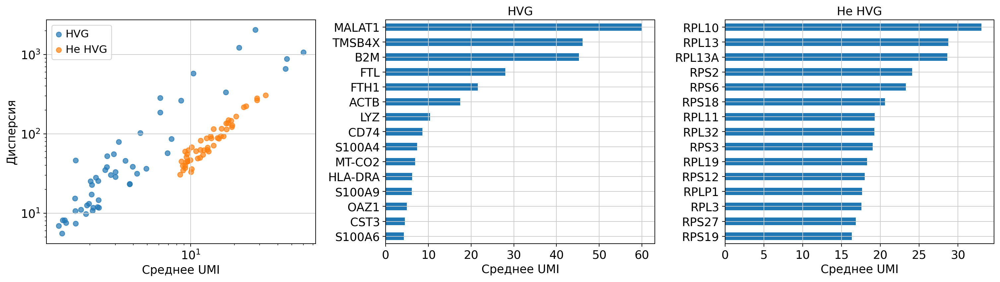

In [31]:
counts = filtered.layers["counts"]
mean = np.asarray(counts.mean(axis=0)).ravel()
variance = np.asarray(counts.power(2).mean(axis=0)).ravel() - mean**2
stats = pd.DataFrame({"mean_umi": mean, "variance": variance, "HVG": hvg_masks["seurat_v3"]}, index=filtered.var_names)
top_sets = {}
for label, mask in [("HVG", stats.HVG), ("Не HVG", ~stats.HVG)]:
    top = stats.loc[mask].nlargest(50, "mean_umi")
    top_sets[label] = top
    print(label, "50 самых экспрессируемых генов")
    display(top)
    print("Среднее UMI / медиана дисперсии:", round(top.mean_umi.mean(), 3), round(top.variance.median(), 3))
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for label, top in top_sets.items():
    axes[0].scatter(top.mean_umi, top.variance, label=label, alpha=.7)
axes[0].set(xscale="log", yscale="log", xlabel="Среднее UMI", ylabel="Дисперсия")
axes[0].legend()
for ax, (label, top) in zip(axes[1:], top_sets.items()):
    top.mean_umi.head(15).sort_values().plot.barh(ax=ax)
    ax.set(title=label, xlabel="Среднее UMI")
plt.tight_layout()
plt.show()

У 50 самых активных HVG средняя экспрессия равна 7,15 UMI, а у 50 самых активных не-HVG 14,33 UMI, медианы дисперсии равны 29,46 и 67,72. Среди не-HVG много RPL/RPS, а среди HVG есть иммунные гены LYZ, LST1, NKG7 и CD74/HLA, а также FTL/FTH1, связанные с обменом железа. Для отбора важен разброс с учетом среднего уровня экспрессии, а не просто большое число UMI.

## Задание 5. Влияние QC-метрик на PCA

Постройте несколько PCA plots для случаев:

1. Не используя фильтрацию и QC и не используя поиск HVG.
2. Не используя фильтрацию и QC, но используя поиск HVG.
3. Используя фильтрацию и QC, но не используя поиск HVG.
4. Используя фильтрацию и QC и используя поиск HVG.

Окрашивайте клетки по:

1. `total_counts` — общее число UMI клетки.
2. `n_genes_by_counts` — число обнаруженных генов.
3. `pct_counts_mt` — доля митохондриальных UMI.
4. Доле рибосомных UMI из задания 1.

Дополнительно постройте scatter plot:

- X — `total_counts`
- Y — `n_genes_by_counts`
- цвет — `pct_counts_mt`

Теперь повторите анализ не используя фильтрацию и QC но используя HVG

**Вопросы:** Связано ли положение клеток на PCA с количеством зарегистрированных UMI? Есть ли направления, вдоль которых меняется доля митохондриальных транскриптов? Можно ли по этим графикам заподозрить, что технические факторы влияют на главные компоненты?

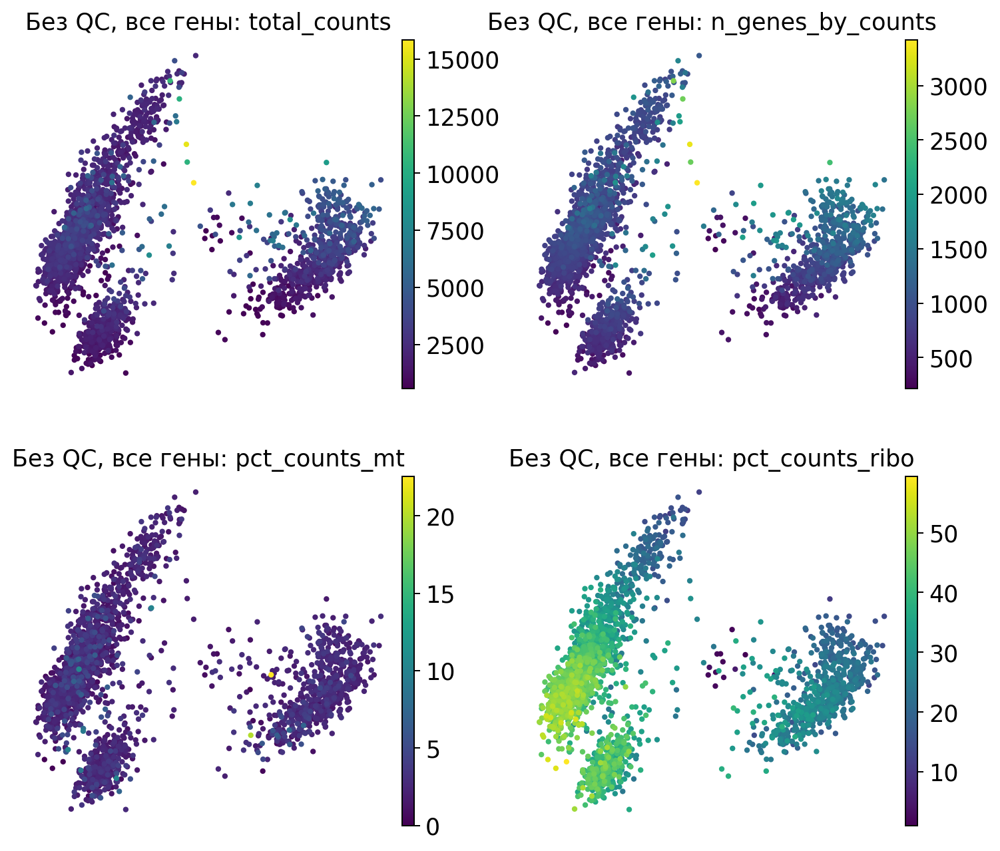

Без QC, все гены


,PC1,PC2
total_counts,0.153,0.348
n_genes_by_counts,0.336,0.554
pct_counts_mt,0.159,-0.054
pct_counts_ribo,-0.829,-0.335


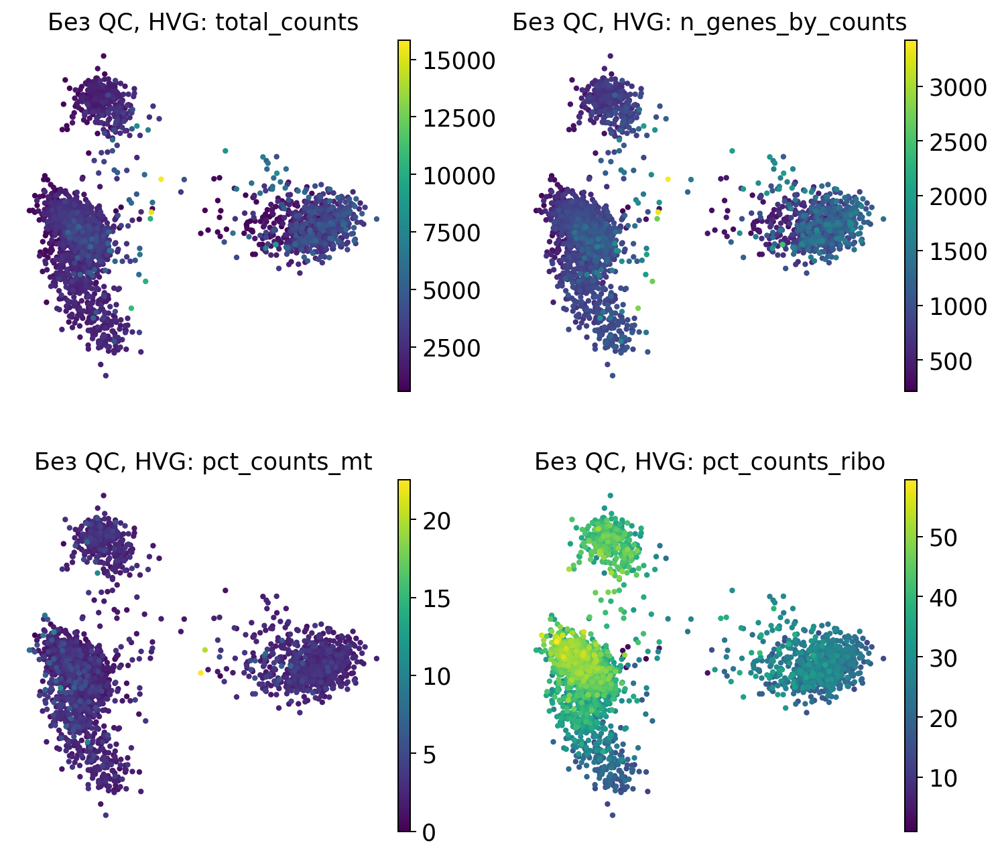

Без QC, HVG


,PC1,PC2
total_counts,0.266,-0.083
n_genes_by_counts,0.375,-0.266
pct_counts_mt,0.094,-0.036
pct_counts_ribo,-0.656,0.322


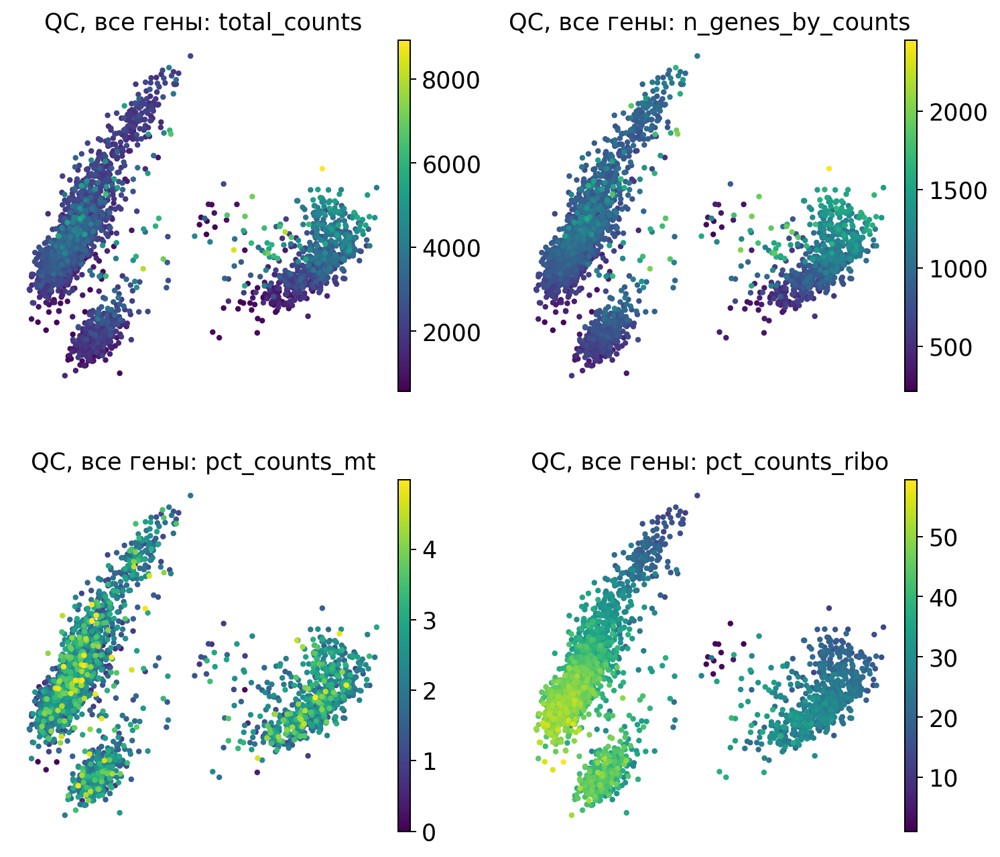

QC, все гены


,PC1,PC2
total_counts,0.155,0.296
n_genes_by_counts,0.343,0.512
pct_counts_mt,0.173,-0.032
pct_counts_ribo,-0.833,-0.353


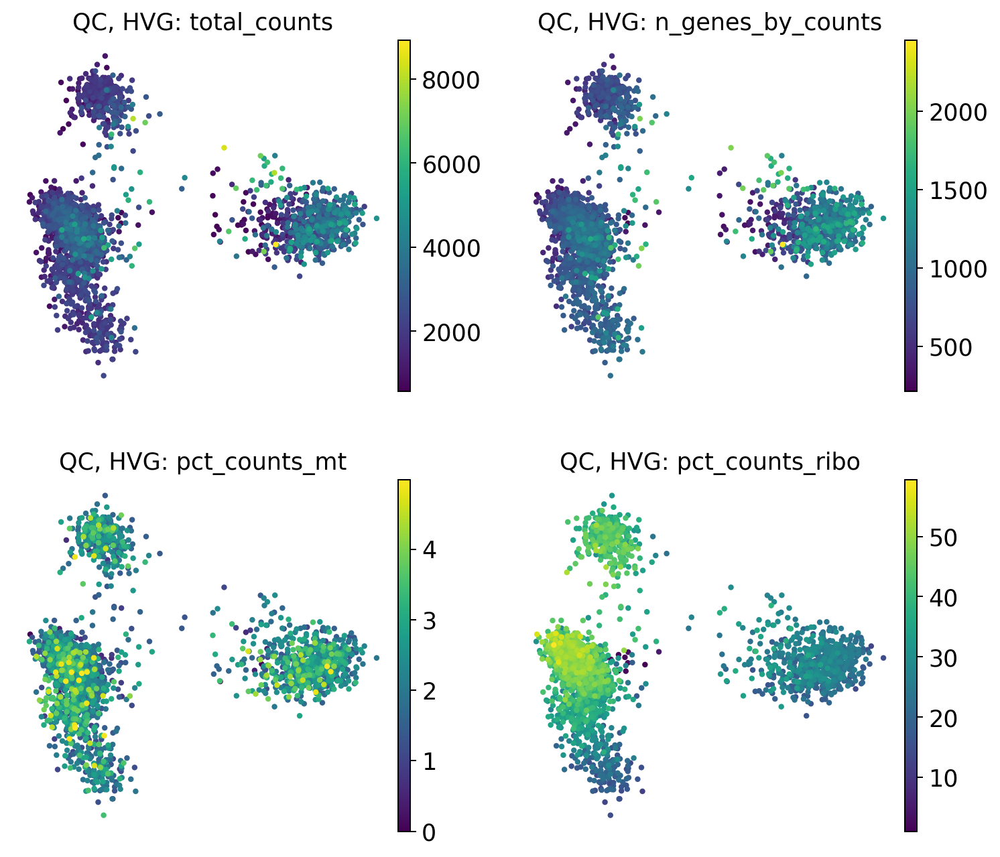

QC, HVG


,PC1,PC2
total_counts,0.243,-0.066
n_genes_by_counts,0.361,-0.257
pct_counts_mt,0.129,-0.043
pct_counts_ribo,-0.678,0.339


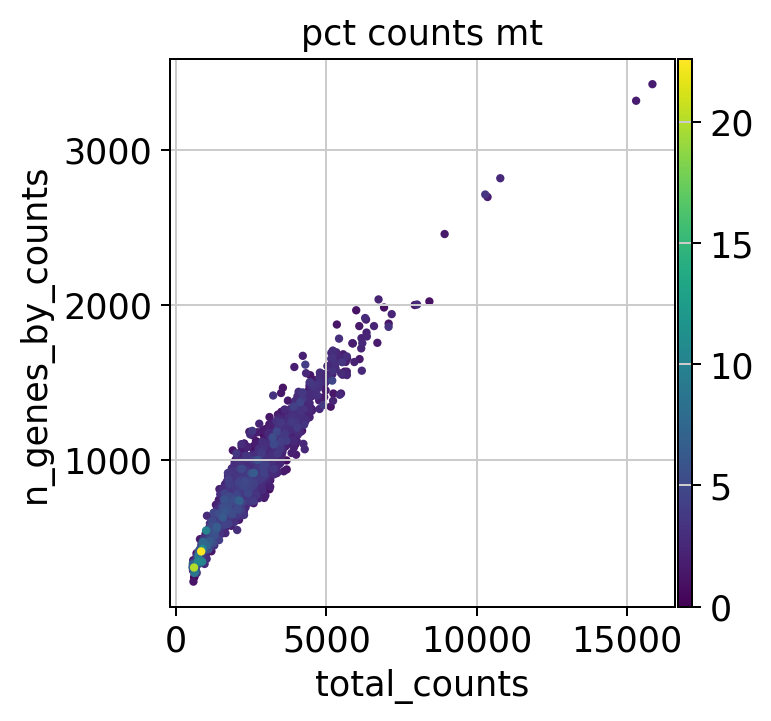

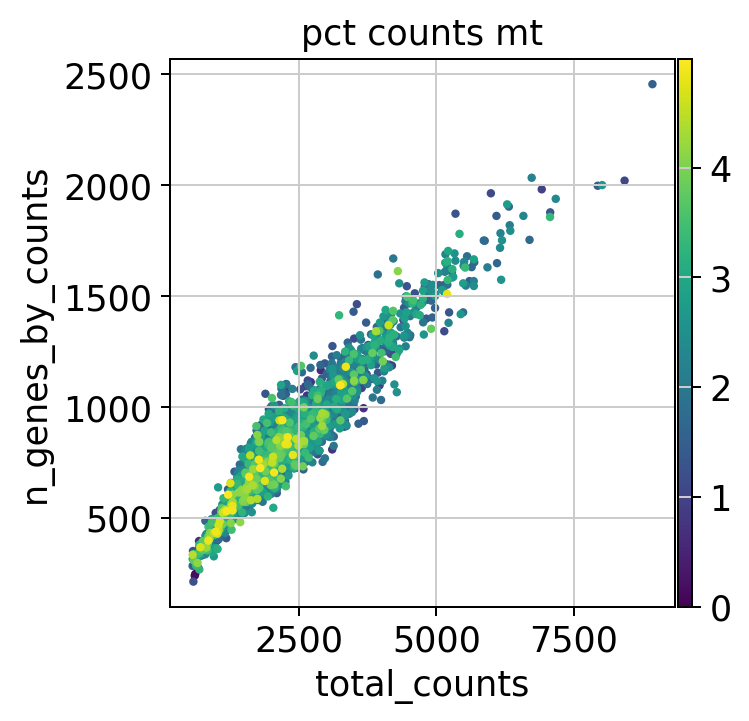

Повтор без QC с HVG воспроизводим: True


In [32]:
qc_pcas = {}
for label, source, use_hvg in [("Без QC, все гены", raw, False), ("Без QC, HVG", raw, True), ("QC, все гены", filtered, False), ("QC, HVG", filtered, True)]:
    a = pca_variant(source, hvg=use_hvg)
    qc_pcas[label] = a
    fields = ["total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo"]
    sc.pl.pca(a, color=fields, ncols=2, title=[f"{label}: {k}" for k in fields])
    print(label)
    display(pc_correlations(a, fields).round(3))
sc.pl.scatter(raw, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt")
sc.pl.scatter(filtered, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt")
repeat_no_qc = pca_variant(raw, hvg=True)
print("Повтор без QC с HVG воспроизводим:", np.allclose(repeat_no_qc.obsm["X_pca"], qc_pcas["Без QC, HVG"].obsm["X_pca"]))

PC1 сильнее всего связан с долей RPS/RPL, корреляция после QC равна -0,833 для всех генов и -0,678 для HVG. После QC с HVG связь PC1 с числом UMI слабее и равна 0,243, а с митохондриальной долей только 0,129. Значит, обработка не убрала все различия в составе РНК, но часть этих различий может быть связана с типами клеток.


## Задание 6. Какие гены формируют главные компоненты?

PCA строит новые признаки как линейные комбинации исходных генов.

Для первой компоненты:

$$
PC_1=a_1Z_1+a_2Z_2+\ldots+a_nZ_n
$$

Коэффициенты $a_i$ называются *loadings*.

Получите 10 генов с наибольшими положительными и 10 с наиболее отрицательными loadings для PC1 и PC2.

Постройте график loadings и графики экспрессии нескольких найденных генов на PCA.

**Вопросы:** Какие гены сильнее всего определяют PC1 и PC2? Связаны ли они с иммунными клеточными популяциями, клеточным циклом или QC-метриками? Можно ли биологически интерпретировать главные компоненты на основании этих генов?

,loading
LTB,-0.112827
IL32,-0.106144
MALAT1,-0.067260
IL7R,-0.059417
CCL5,-0.051053
CD2,-0.045544
CTSW,-0.043735
STK17A,-0.037906
ACAP1,-0.036313
CD247,-0.036139


,loading
NKG7,-0.216003
S100A4,-0.180781
CCL5,-0.165346
IL32,-0.144602
GNLY,-0.134454
CTSW,-0.134234
GZMA,-0.134097
CST7,-0.131238
SRGN,-0.123198
ANXA1,-0.120073


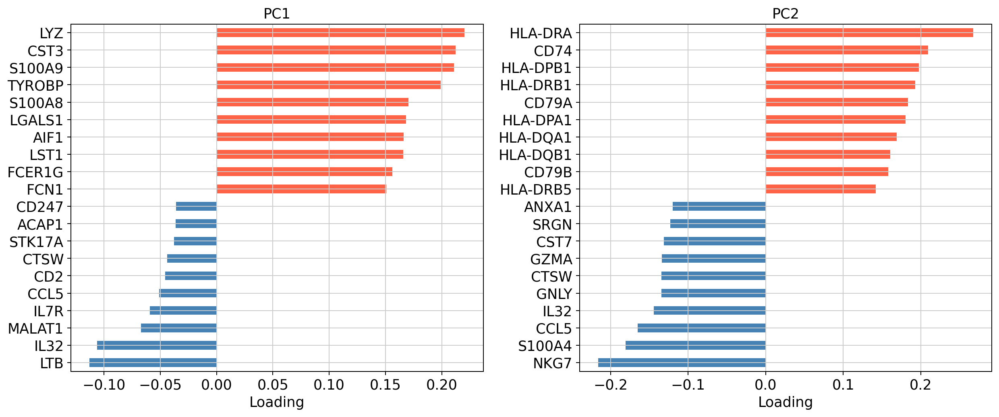

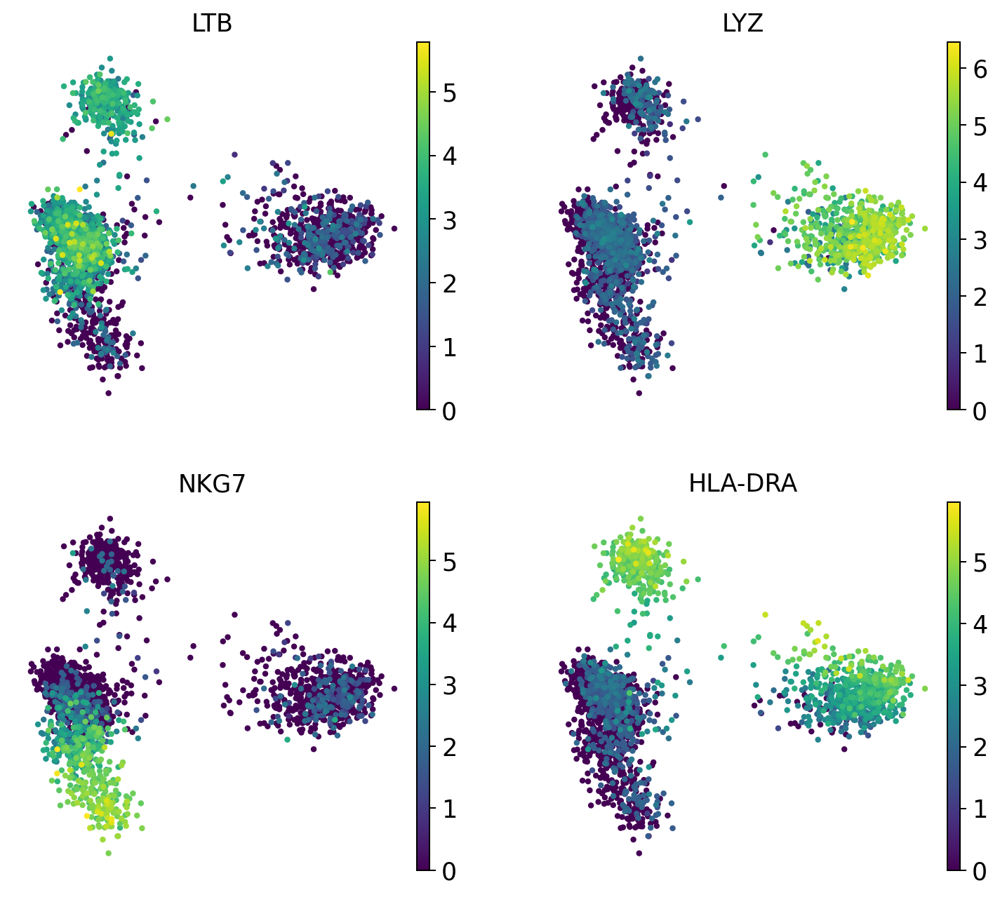

,PC1,PC2
total_counts,0.243,-0.066
n_genes_by_counts,0.361,-0.257
pct_counts_mt,0.129,-0.043
pct_counts_ribo,-0.678,0.339


In [33]:
a = hvg_pca
loadings = pd.DataFrame(a.varm["PCs"][:, :2], index=a.var_names, columns=["PC1", "PC2"])
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
selected = []
for pc, ax in zip(loadings, axes):
    top = pd.concat([loadings[pc].nsmallest(10), loadings[pc].nlargest(10)]).sort_values()
    display(top.to_frame("loading"))
    top.plot.barh(ax=ax, color=np.where(top > 0, "tomato", "steelblue"))
    ax.set(title=pc, xlabel="Loading")
    selected.extend([top.index[0], top.index[-1]])
plt.tight_layout()
plt.show()
sc.pl.pca(a, color=list(dict.fromkeys(selected)), ncols=2)
display(pc_correlations(a, ["total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo"]).round(3))

На разных концах PC1 находятся клетки с миелоидными генами LYZ, CST3, S100A9 и TYROBP и клетки с лимфоцитарными LTB, IL32, IL7R и CD2. PC2 отделяет HLA-DRA, CD74 и CD79A/B от NKG7, GNLY, CCL5 и GZMA, то есть отражает различия между иммунными группами. Гены клеточного цикла здесь не главные, а знак компоненты можно поменять без изменения смысла.

## Задание 7
- Постройте график PCA не используя логарифмирование log1p
- Постройте график PCA не используя логарифмирование log1p и нормализацию normalize
- Попробуйте дополнительно к нормализации и логарифмированию использовать `sc.pp.scale(adata)`

`sc.pp.scale(adata)` делает стандартизацию генов по столбцам клеток.

**Вопросы:** Что сильнее влияет на PCA - нормализация или логарифмирование? Сильно ли помогает scale? Что нам даёт каждая процедура: логарифмирование, нормализация, стандартизация; как они влияют на PCA? Все ли их нужно делать перед PCA?

/usr/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


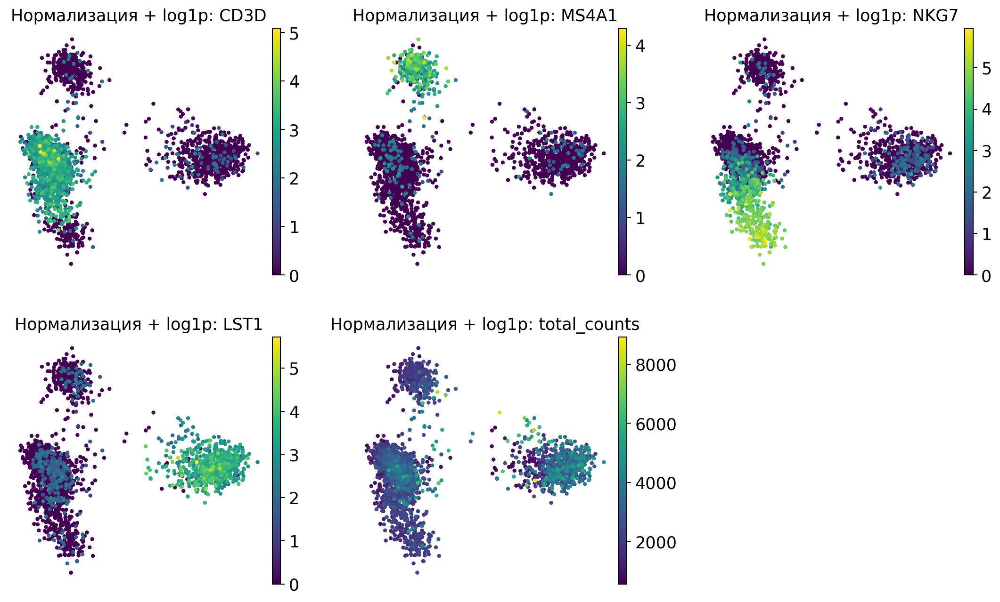

Нормализация + log1p дисперсия PC1+PC2: 0.1326


,PC1,PC2
total_counts,0.243,-0.066
pct_counts_mt,0.129,-0.043


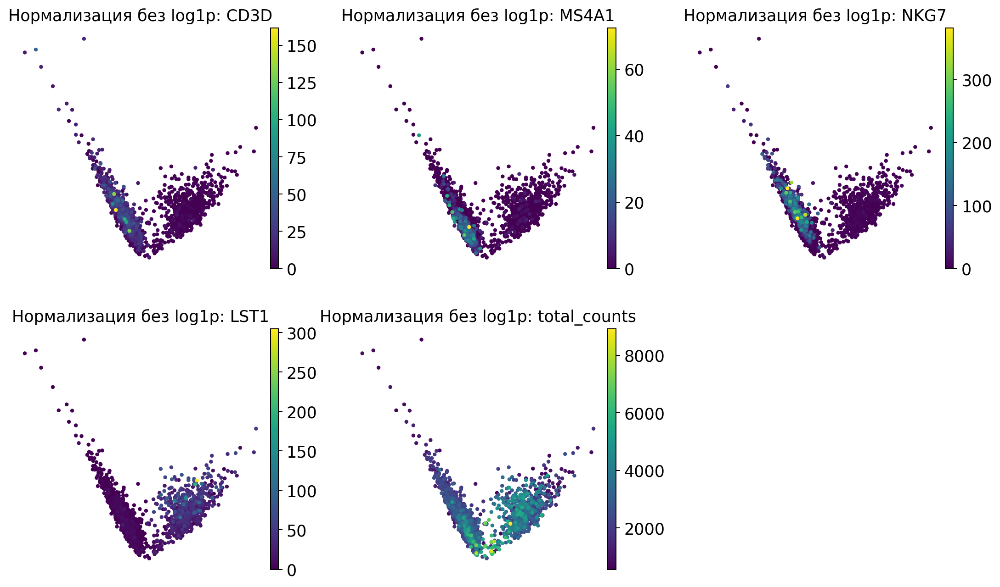

Нормализация без log1p дисперсия PC1+PC2: 0.5032


,PC1,PC2
total_counts,0.268,-0.211
pct_counts_mt,0.096,0.090


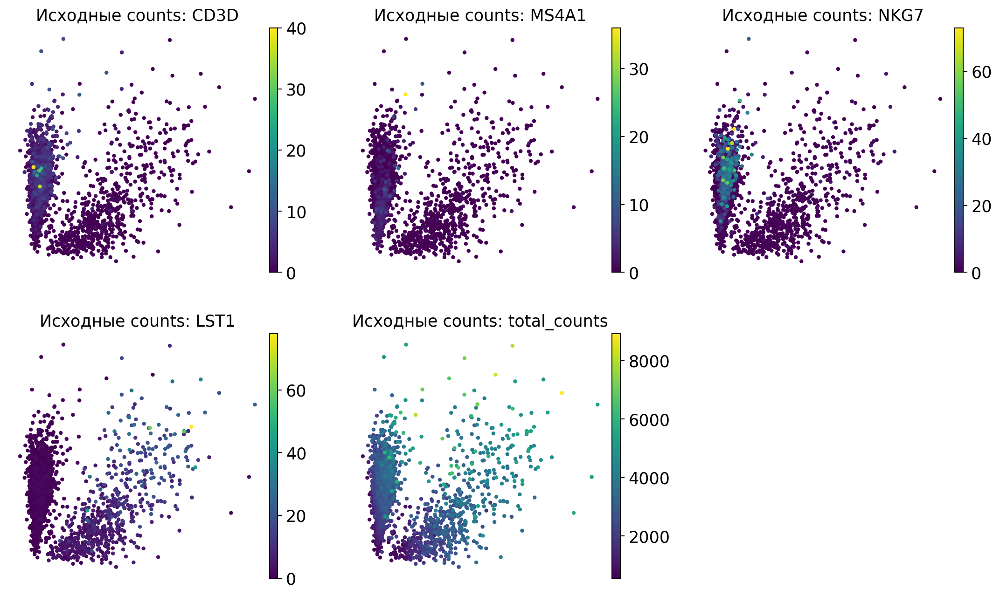

Исходные counts дисперсия PC1+PC2: 0.5837


,PC1,PC2
total_counts,0.490,0.512
pct_counts_mt,0.078,-0.082


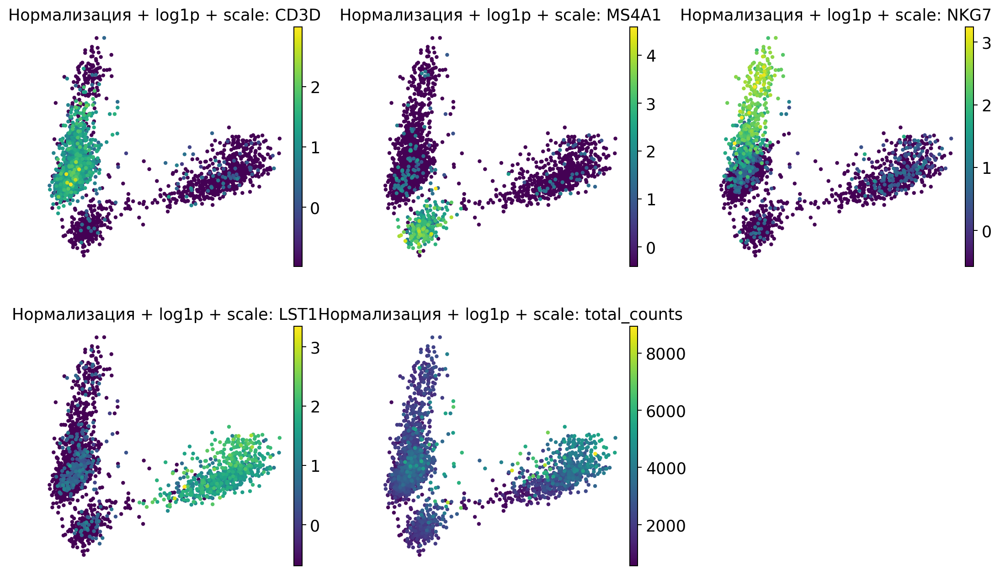

Нормализация + log1p + scale дисперсия PC1+PC2: 0.0407


,PC1,PC2
total_counts,0.291,0.326
pct_counts_mt,0.126,0.009


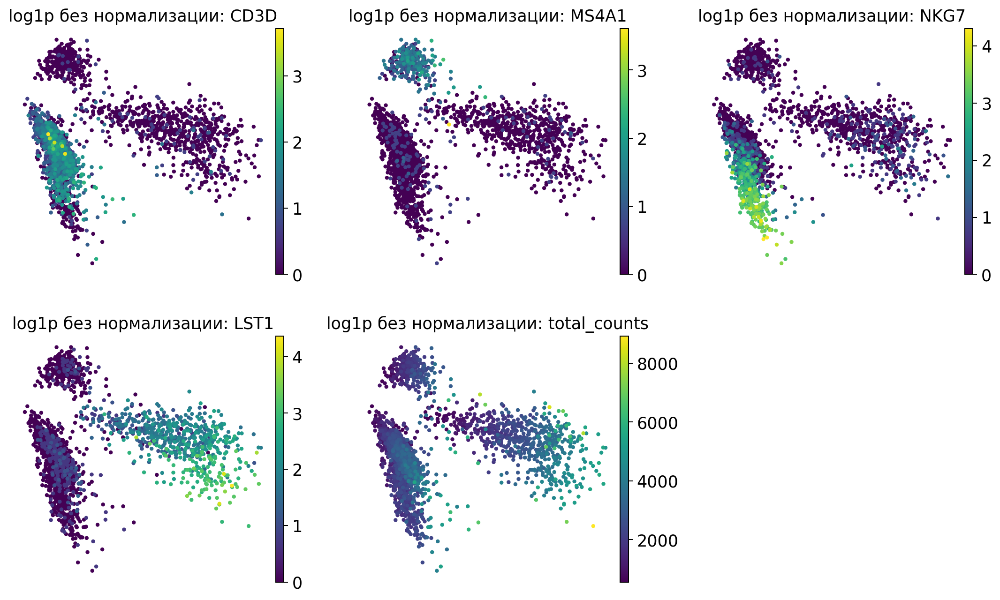

log1p без нормализации дисперсия PC1+PC2: 0.2272


,PC1,PC2
total_counts,0.504,-0.342
pct_counts_mt,0.099,0.026


In [34]:
transforms = {
    "Нормализация + log1p": hvg_pca,
    "Нормализация без log1p": pca_variant(filtered, logarithm=False),
    "Исходные counts": pca_variant(filtered, normalize=False, logarithm=False),
    "Нормализация + log1p + scale": pca_variant(filtered, scale=True),
    "log1p без нормализации": pca_variant(filtered, normalize=False)
}
for label, a in transforms.items():
    sc.pl.pca(a, color=markers + ["total_counts"], ncols=3, title=[f"{label}: {g}" for g in markers + ["total_counts"]])
    print(label, "дисперсия PC1+PC2:", round(float(a.uns["pca"]["variance_ratio"][:2].sum()), 4))
    display(pc_correlations(a, ["total_counts", "pct_counts_mt"]).round(3))

Без нормализации PC1 сильнее связан с числом UMI, корреляция равна 0,490 на counts и 0,504 после одного log1p, а после обеих процедур 0,243. Добавление log1p после нормализации снижает долю первых двух компонент с 50,32% до 13,26% и уменьшает влияние самых активных генов. Scale снижает эту долю до 4,07%, но явного улучшения не дает, поэтому здесь он необязателен. Нормализация учитывает разное число считанных UMI, log1p сжимает большие значения, а scale выравнивает разброс между генами.

## Дополнительное задание. Клеточный цикл и PCA

Используйте наборы генов фаз S и G2/M, чтобы вычислить оценки активности программ клеточного цикла для каждой клетки.

Определите предполагаемую фазу клеточного цикла и постройте PCA, окрашенный по:

- `S_score`
- `G2M_score`
- `phase`

**Вопросы:** Разделяются ли клетки по фазам клеточного цикла? Можно ли обнаружить связь клеточного цикла с PC1 или PC2? Почему клетки одного типа могут отличаться по экспрессии генов клеточного цикла?

Найдены гены S / G2M: 36 44


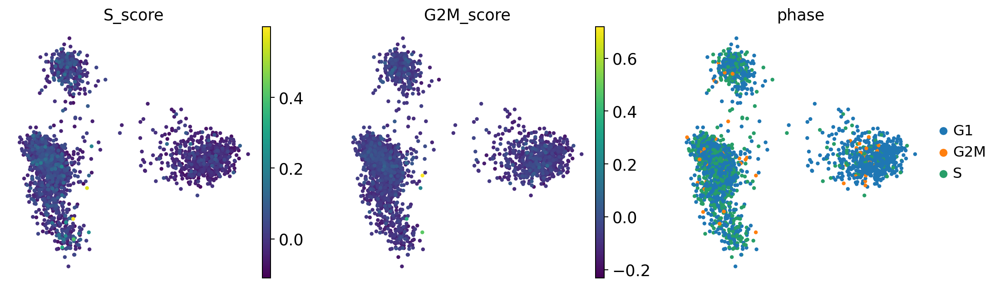

,Клеток
phase,
G1,1691
S,863
G2M,84


,PC1,PC2
S_score,-0.226,-0.023
G2M_score,-0.040,0.081


In [35]:
s_genes = "MCM5 PCNA TYMS FEN1 MCM2 MCM4 RRM1 UNG GINS2 MCM6 CDCA7 DTL PRIM1 UHRF1 HELLS RFC2 RPA2 NASP RAD51AP1 GMNN WDR76 SLBP CCNE2 UBR7 POLD3 MSH2 ATAD2 RAD51 RRM2 CDC45 CDC6 EXO1 TIPIN DSCC1 BLM CASP8AP2 USP1 CLSPN POLA1 CHAF1B BRIP1 E2F8".split()
g2m_genes = "HMGB2 CDK1 NUSAP1 UBE2C BIRC5 TPX2 TOP2A NDC80 CKS2 NUF2 CKS1B MKI67 TMPO CENPF TACC3 FAM64A SMC4 CCNB2 CKAP2L CKAP2 AURKB BUB1 KIF11 ANP32E TUBB4B GTSE1 KIF20B HJURP CDCA3 HN1 CDC20 TTK CDC25C KIF2C RANGAP1 NCAPD2 DLGAP5 CDCA2 CDCA8 ECT2 KIF23 HMMR AURKA PSRC1 ANLN LBR CKAP5 CENPE CTCF NEK2 G2E3 GAS2L3 CBX5 CENPA".split()
cycle = hvg_pca.copy()
s_found = [g for g in s_genes if g in cycle.var_names]
g2m_found = [g for g in g2m_genes if g in cycle.var_names]
print("Найдены гены S / G2M:", len(s_found), len(g2m_found))
sc.tl.score_genes_cell_cycle(cycle, s_genes=s_found, g2m_genes=g2m_found, random_state=42, use_raw=False)
sc.pl.pca(cycle, color=["S_score", "G2M_score", "phase"], ncols=3)
display(cycle.obs.phase.value_counts().to_frame("Клеток"))
display(pc_correlations(cycle, ["S_score", "G2M_score"]).round(3))

Найдены 36 генов S и 44 G2/M, а клетки получили 1691 метку G1, 863 S и 84 G2M. Четкого разделения фаз на PCA нет. Связь S_score с PC1 слабая и равна -0,226, а для G2M_score связь с первыми двумя PC не больше 0,081 по модулю. Клетки одного типа могут отличаться по активности деления и числу считанных РНК, поэтому эти метки сами по себе не доказывают активное деление.

Наборы генов взяты из примера Seurat по клеточному циклу.
https://satijalab.org/seurat/articles/cell_cycle_vignette.html